# Imbalance Handling: Weighted Loss and Class-Balanced Sampling

## Setup

In [25]:
import fnmatch
import os
import shutil
from pathlib import Path

WORKING = Path("/kaggle/working")


def find_input_file(pattern):
    for folder, subfolders, files in os.walk("/kaggle/input"):
        subfolders[:] = [name for name in subfolders if name not in ("color", "grayscale", "segmented")]
        for name in sorted(files):
            if fnmatch.fnmatch(name, pattern):
                return Path(folder) / name
    raise FileNotFoundError(f"{pattern} not found in /kaggle/input. Add the dataset that contains it.")


for pattern, target in [("split.csv", "split.csv"),
                        ("train_baseline*.py*", "train_baseline.py"),
                        ("augmentation_pipeline*.py*", "augmentation_pipeline.py")]:
    source = find_input_file(pattern)
    shutil.copy(source, WORKING / target)
    print(f"Copied {source} -> {WORKING / target}")


Copied /kaggle/input/datasets/shahnawaz006/week3-inputdata/split.csv -> /kaggle/working/split.csv
Copied /kaggle/input/datasets/shahnawaz006/week3-inputdata/train_baseline (1).py.txt -> /kaggle/working/train_baseline.py
Copied /kaggle/input/datasets/shahnawaz006/week3-inputdata/augmentation_pipeline (1).py.txt -> /kaggle/working/augmentation_pipeline.py


## Write the Script

In [26]:
%%writefile /kaggle/working/imbalance_experiments.py
import argparse
import json
import time
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import f1_score

import train_baseline as baseline
from augmentation_pipeline import build_eval_transform

VARIANTS = [
    ("baseline", None, "uniform"),
    ("weighted_loss_inverse", "inverse", "uniform"),
    ("weighted_loss_sqrt_inverse", "sqrt_inverse", "uniform"),
    ("weighted_loss_effective_number", "effective_number", "uniform"),
    ("sampling_sqrt", None, "sqrt"),
    ("sampling_balanced", None, "balanced"),
]


def parse_args():
    parser = argparse.ArgumentParser()
    parser.add_argument("--csv", required=True)
    parser.add_argument("--root", default="")
    parser.add_argument("--out", default="results_imbalance")
    parser.add_argument("--features", default="features_cache.pt")
    parser.add_argument("--epochs", type=int, default=30)
    parser.add_argument("--lr", type=float, default=1e-3)
    parser.add_argument("--weight-decay", type=float, default=1e-4)
    parser.add_argument("--batch", type=int, default=256)
    parser.add_argument("--extract-batch", type=int, default=128)
    parser.add_argument("--workers", type=int, default=2)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--beta", type=float, default=0.999)
    return parser.parse_args()


def load_features(args, device, parts, class_to_index):
    cache = Path(args.features)
    if cache.exists():
        features = torch.load(cache, map_location="cpu")
        for split, frame in parts.items():
            if len(features[split][0]) != len(frame):
                raise ValueError(
                    f"{cache} does not match the split file for '{split}'. Delete it and run again."
                )
        print(f"Loaded cached features from {cache}")
        return features

    baseline.check_paths(pd.concat(parts.values()), args.root)
    backbone = baseline.build_backbone("imagenet", device)
    extract_args = argparse.Namespace(batch=args.extract_batch, workers=args.workers)
    transform = build_eval_transform(normalize=True)
    features = {}
    started = time.time()
    for split in ("val", "test", "train"):
        dataset = baseline.CsvDataset(parts[split], class_to_index, transform, args.root)
        features[split] = baseline.extract(backbone, dataset, device, extract_args, f"features: {split}")
    torch.save(features, cache)
    print(f"Feature extraction done in {time.time() - started:.0f}s, saved to {cache}")
    return features


def class_weights(counts, scheme, beta):
    counts = counts.astype(np.float64)
    if scheme == "inverse":
        weights = 1.0 / counts
    elif scheme == "sqrt_inverse":
        weights = 1.0 / np.sqrt(counts)
    elif scheme == "effective_number":
        weights = (1.0 - beta) / (1.0 - np.power(beta, counts))
    else:
        raise ValueError(f"Unknown weighting scheme: {scheme}")
    weights = weights / weights.sum() * len(counts)
    return torch.tensor(weights, dtype=torch.float32)


def sampling_probabilities(labels, counts, scheme, device):
    if scheme == "uniform":
        return None
    exponent = 1.0 if scheme == "balanced" else 0.5
    per_class = 1.0 / np.power(counts.astype(np.float64), exponent)
    probabilities = per_class[labels.cpu().numpy()]
    return torch.tensor(probabilities / probabilities.sum(), dtype=torch.float32, device=device)


def run_variant(name, scheme, sampling, data, counts, names, args, device, out_dir):
    variant_dir = out_dir / name
    variant_dir.mkdir(parents=True, exist_ok=True)
    X_train, y_train = data["train"]
    X_val, y_val = data["val"]
    X_test, y_test = data["test"]

    weight = None
    if scheme is not None:
        weight = class_weights(counts, scheme, args.beta)
        print(f"  class weights: min {weight.min():.3f} | max {weight.max():.3f}")
        weight = weight.to(device)
    sample_probabilities = sampling_probabilities(y_train, counts, sampling, device)

    baseline.set_seed(args.seed)
    head = baseline.make_head(len(names)).to(device)
    optimizer = torch.optim.AdamW(head.parameters(), lr=args.lr, weight_decay=args.weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=args.epochs)
    loss_fn = nn.CrossEntropyLoss(weight=weight)

    history, best_f1, best_epoch, best_state = [], -1.0, -1, None
    for epoch in range(1, args.epochs + 1):
        head.train()
        if sample_probabilities is None:
            order = torch.randperm(len(X_train), device=device)
        else:
            order = torch.multinomial(sample_probabilities, len(X_train), replacement=True)
        total, seen = 0.0, 0
        for start in range(0, len(order), args.batch):
            batch = order[start:start + args.batch]
            optimizer.zero_grad()
            loss = loss_fn(head(X_train[batch]), y_train[batch])
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)
            seen += len(batch)
        scheduler.step()

        val_predictions = baseline.predict(head, X_val, device)
        val_f1 = f1_score(y_val.numpy(), val_predictions, average="macro", zero_division=0)
        history.append({"epoch": epoch, "train_loss": total / seen, "val_macro_f1": val_f1})
        if val_f1 > best_f1:
            best_f1, best_epoch = val_f1, epoch
            best_state = {key: value.detach().cpu().clone() for key, value in head.state_dict().items()}

    pd.DataFrame(history).to_csv(variant_dir / "training_curve.csv", index=False)
    torch.save({"head": best_state, "classes": names}, variant_dir / "head_best.pt")
    head.load_state_dict(best_state)

    results = {"variant": name, "best_epoch": best_epoch}
    test_table = None
    for split, X, y in (("val", X_val, y_val), ("test", X_test, y_test)):
        predictions = baseline.predict(head, X, device)
        summary, table, _, _ = baseline.evaluate(y.numpy(), predictions, names)
        results[f"{split}_accuracy"] = summary["accuracy"]
        results[f"{split}_macro_f1"] = summary["macro_f1"]
        table.to_csv(variant_dir / f"{split}_per_class.csv", index=False)
        if split == "test":
            test_table = table
    print(f"  best epoch {best_epoch} | val macro-F1 {results['val_macro_f1']:.4f} "
          f"| test macro-F1 {results['test_macro_f1']:.4f}")
    return results, test_table


def plot_summary(summary, comparison, winner, path):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    positions = np.arange(len(summary))
    axes[0].bar(positions - 0.2, summary["val_macro_f1"], 0.4, label="val")
    axes[0].bar(positions + 0.2, summary["test_macro_f1"], 0.4, label="test")
    low = min(summary["val_macro_f1"].min(), summary["test_macro_f1"].min())
    axes[0].set_ylim(max(0.0, low - 0.01), 1.0)
    axes[0].set_xticks(positions)
    axes[0].set_xticklabels(summary["variant"], rotation=30, ha="right", fontsize=8)
    axes[0].set_ylabel("Macro F1")
    axes[0].set_title("Macro F1 by variant")
    axes[0].legend()

    ordered = comparison.sort_values("train_images")
    change = ordered[f"{winner}_f1"].values - ordered["baseline_f1"].values
    axes[1].bar(range(len(ordered)), change, color=np.where(change >= 0, "tab:green", "tab:red"))
    axes[1].set_xticks(range(len(ordered)))
    axes[1].set_xticklabels(ordered["class"], rotation=90, fontsize=6)
    axes[1].set_ylabel("Test F1 change vs baseline")
    axes[1].set_title(f"{winner}: per-class change (smallest classes on the left)")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def main():
    args = parse_args()
    out_dir = Path(args.out)
    out_dir.mkdir(parents=True, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device)

    df = baseline.load_split(args.csv)
    names = sorted(df["class"].unique())
    class_to_index = {name: i for i, name in enumerate(names)}
    parts = {key: df[df.split == key].reset_index(drop=True) for key in ("train", "val", "test")}
    print(f"{len(names)} classes | " + " | ".join(f"{key} {len(value)}" for key, value in parts.items()))

    features = load_features(args, device, parts, class_to_index)
    data = {
        "train": (features["train"][0].to(device), features["train"][1].to(device)),
        "val": features["val"],
        "test": features["test"],
    }
    counts = np.bincount(features["train"][1].numpy(), minlength=len(names))

    summaries = []
    comparison = pd.DataFrame({"class": names, "train_images": counts})
    for name, scheme, sampling in VARIANTS:
        print(f"\n[{name}]")
        results, test_table = run_variant(name, scheme, sampling, data, counts, names, args, device, out_dir)
        summaries.append(results)
        comparison[f"{name}_f1"] = test_table["f1"].values
        comparison[f"{name}_recall"] = test_table["recall"].values

    summary = pd.DataFrame(summaries)
    winner = summary.sort_values("val_macro_f1", ascending=False).iloc[0]["variant"]
    summary.to_csv(out_dir / "imbalance_summary.csv", index=False)
    comparison.to_csv(out_dir / "per_class_comparison.csv", index=False)
    plot_summary(summary, comparison, winner, out_dir / "imbalance_comparison.png")

    head = baseline.make_head(len(names)).to(device)
    head.load_state_dict(torch.load(out_dir / winner / "head_best.pt", map_location=device)["head"])
    predictions = baseline.predict(head, data["test"][0], device)
    _, _, matrix, _ = baseline.evaluate(data["test"][1].numpy(), predictions, names)
    baseline.plot_cm(matrix, names, f"Confusion matrix (test, {winner})",
                     out_dir / "winner_confusion_matrix.png")

    (out_dir / "metrics.json").write_text(json.dumps(
        {"winner_by_val_macro_f1": winner, "variants": summary.to_dict("records")},
        indent=2, default=lambda value: value.item()))

    print("\n=== SUMMARY (winner chosen by val macro-F1) ===")
    print(summary.round(4).to_string(index=False))
    print(f"\nWinner: {winner}")
    columns = ["class", "train_images", "baseline_f1", f"{winner}_f1"]
    print("\nSmallest classes by training images (test F1):")
    print(comparison.sort_values("train_images").head(5)[columns].round(4).to_string(index=False))
    print("\nWeakest baseline classes (test F1):")
    print(comparison.nsmallest(5, "baseline_f1")[columns].round(4).to_string(index=False))
    print(f"\nSaved to {out_dir}/")


if __name__ == "__main__":
    main()


Overwriting /kaggle/working/imbalance_experiments.py


## Smoke Test 

In [27]:
import numpy as np
import pandas as pd
import torch

rng = np.random.default_rng(0)
n_classes = 38
train_counts = np.linspace(200, 12, n_classes).astype(int)

rows = []
labels = {"train": [], "val": [], "test": []}
for split, scale in (("train", 1.0), ("val", 0.2), ("test", 0.2)):
    for class_id in range(n_classes):
        for i in range(max(3, int(train_counts[class_id] * scale))):
            rows.append({"path": f"class_{class_id:02d}/{split}_{i}.jpg",
                         "class": f"class_{class_id:02d}", "split": split})
            labels[split].append(class_id)

pd.DataFrame(rows).to_csv("/kaggle/working/smoke_split.csv", index=False)

centers = torch.randn(n_classes, 2048)
features = {}
for split in ("train", "val", "test"):
    y = torch.tensor(labels[split])
    features[split] = (centers[y] + 2.0 * torch.randn(len(y), 2048), y)
torch.save(features, "/kaggle/working/smoke_features.pt")

print({split: len(values) for split, values in labels.items()})


{'train': 4010, 'val': 781, 'test': 781}


In [28]:
!cd /kaggle/working && python imbalance_experiments.py --csv smoke_split.csv --features smoke_features.pt --out smoke_results --epochs 2 --batch 64


Device: cuda
38 classes | train 4010 | val 781 | test 781
Loaded cached features from smoke_features.pt

[baseline]
  best epoch 1 | val macro-F1 1.0000 | test macro-F1 1.0000

[weighted_loss_inverse]
  class weights: min 0.314 | max 5.238
  best epoch 1 | val macro-F1 1.0000 | test macro-F1 1.0000

[weighted_loss_sqrt_inverse]
  class weights: min 0.611 | max 2.492
  best epoch 1 | val macro-F1 1.0000 | test macro-F1 1.0000

[weighted_loss_effective_number]
  class weights: min 0.336 | max 5.106
  best epoch 1 | val macro-F1 1.0000 | test macro-F1 1.0000

[sampling_sqrt]
  best epoch 1 | val macro-F1 1.0000 | test macro-F1 1.0000

[sampling_balanced]
  best epoch 1 | val macro-F1 1.0000 | test macro-F1 1.0000

=== SUMMARY (winner chosen by val macro-F1) ===
                       variant  best_epoch  val_accuracy  val_macro_f1  test_accuracy  test_macro_f1
                      baseline           1           1.0           1.0            1.0            1.0
         weighted_loss_invers

## Run

In [29]:
import os
from pathlib import Path


def find_color_root():
    for folder, subfolders, _ in os.walk("/kaggle/input"):
        if "color" in subfolders:
            return Path(folder) / "color"
        subfolders[:] = [name for name in subfolders if name not in ("grayscale", "segmented")]
    raise FileNotFoundError("No 'color' folder found. Add the PlantVillage dataset.")


ROOT = str(find_color_root())
print("Image root:", ROOT)
!cd /kaggle/working && python imbalance_experiments.py --csv split.csv --root {ROOT} --out results_imbalance --workers 4


Image root: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color
Device: cuda
38 classes | train 37751 | val 7976 | test 7978
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|███████████████████████████████████████| 97.8M/97.8M [00:00<00:00, 199MB/s]
features: train: 100%|████████████████████████| 295/295 [16:32<00:00,  3.37s/it]
Feature extraction done in 1421s, saved to features_cache.pt

[baseline]
  best epoch 27 | val macro-F1 0.9689 | test macro-F1 0.9630

[weighted_loss_inverse]
  class weights: min 0.142 | max 5.207
  best epoch 28 | val macro-F1 0.9635 | test macro-F1 0.9626

[weighted_loss_sqrt_inverse]
  class weights: min 0.408 | max 2.469
  best epoch 26 | val macro-F1 0.9670 | test macro-F1 0.9635

[weighted_loss_effective_number]
  class weights: min 0.425 | max 4.168
  best epoch 27 | val macro-F1 0.9660 | test macro-F1 0.9617

[sampling_sqrt]
  best epoch 27 | val macro

## Results

,variant,best_epoch,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1
0,baseline,27,0.9739,0.9689,0.9695,0.9630
1,weighted_loss_inverse,28,0.9718,0.9635,0.9690,0.9626
2,weighted_loss_sqrt_inverse,26,0.9737,0.9670,0.9699,0.9635
3,weighted_loss_effective_number,27,0.9734,0.9660,0.9690,0.9617
4,sampling_sqrt,27,0.9733,0.9673,0.9693,0.9629
5,sampling_balanced,30,0.9729,0.9659,0.9685,0.9622


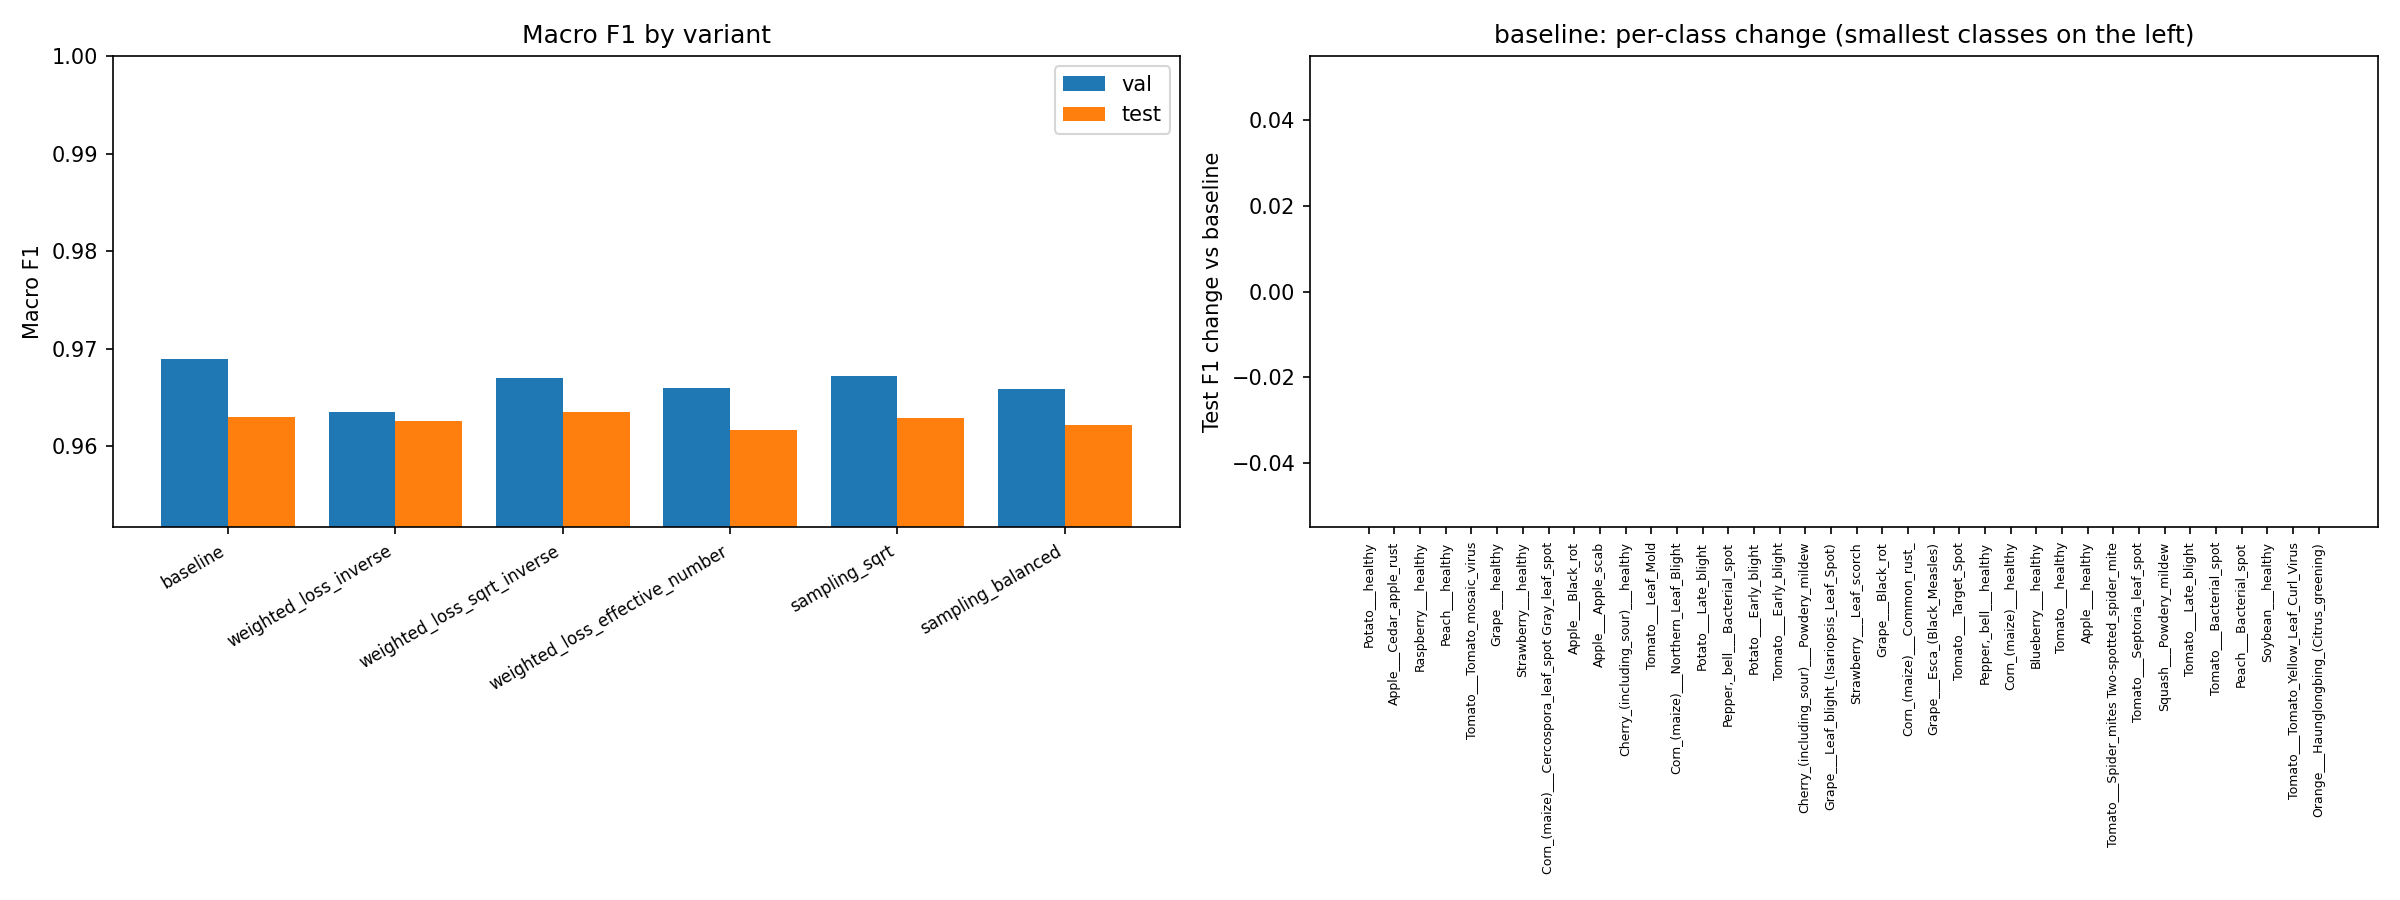

,class,train_images,baseline_f1,baseline_recall,weighted_loss_inverse_f1,weighted_loss_inverse_recall,weighted_loss_sqrt_inverse_f1,weighted_loss_sqrt_inverse_recall,weighted_loss_effective_number_f1,weighted_loss_effective_number_recall,sampling_sqrt_f1,sampling_sqrt_recall,sampling_balanced_f1,sampling_balanced_recall
22,Potato___healthy,105,0.8500,0.7391,0.8444,0.8261,0.8293,0.7391,0.8372,0.7826,0.8500,0.7391,0.8372,0.7826
2,Apple___Cedar_apple_rust,192,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
23,Raspberry___healthy,248,0.9808,0.9623,1.0000,1.0000,0.9905,0.9811,0.9808,0.9623,0.9905,0.9811,1.0000,1.0000
17,Peach___healthy,251,0.9908,0.9818,0.9818,0.9818,0.9908,0.9818,0.9730,0.9818,0.9818,0.9818,0.9818,0.9818
36,Tomato___Tomato_mosaic_virus,257,0.9735,0.9821,0.9655,1.0000,0.9735,0.9821,0.9649,0.9821,0.9735,0.9821,0.9649,0.9821
14,Grape___healthy,293,1.0000,1.0000,0.9922,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
27,Strawberry___healthy,314,0.9927,1.0000,1.0000,1.0000,0.9927,1.0000,0.9927,1.0000,1.0000,1.0000,1.0000,1.0000
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,359,0.8497,0.8442,0.8375,0.8701,0.8590,0.8701,0.8375,0.8701,0.8354,0.8571,0.8323,0.8701
1,Apple___Black_rot,430,0.9783,0.9677,0.9838,0.9785,0.9783,0.9677,0.9838,0.9785,0.9783,0.9677,0.9891,0.9785
0,Apple___Apple_scab,440,0.9789,0.9688,0.9792,0.9792,0.9789,0.9688,0.9792,0.9792,0.9843,0.9792,0.9845,0.9896


In [30]:
import pandas as pd
from IPython.display import Image, display

RESULTS = "/kaggle/working/results_imbalance"
summary = pd.read_csv(f"{RESULTS}/imbalance_summary.csv")
comparison = pd.read_csv(f"{RESULTS}/per_class_comparison.csv")

display(summary.round(4))
display(Image(f"{RESULTS}/imbalance_comparison.png"))
comparison.sort_values("train_images").head(10).round(4)


In [31]:
!cd /kaggle/working && zip -r results_imbalance.zip results_imbalance


  adding: results_imbalance/ (stored 0%)
  adding: results_imbalance/weighted_loss_inverse/ (stored 0%)
  adding: results_imbalance/weighted_loss_inverse/head_best.pt (deflated 8%)
  adding: results_imbalance/weighted_loss_inverse/val_per_class.csv (deflated 57%)
  adding: results_imbalance/weighted_loss_inverse/test_per_class.csv (deflated 57%)
  adding: results_imbalance/weighted_loss_inverse/training_curve.csv (deflated 50%)
  adding: results_imbalance/metrics.json (deflated 72%)
  adding: results_imbalance/baseline/ (stored 0%)
  adding: results_imbalance/baseline/head_best.pt (deflated 8%)
  adding: results_imbalance/baseline/val_per_class.csv (deflated 58%)
  adding: results_imbalance/baseline/test_per_class.csv (deflated 55%)
  adding: results_imbalance/baseline/training_curve.csv (deflated 50%)
  adding: results_imbalance/weighted_loss_sqrt_inverse/ (stored 0%)
  adding: results_imbalance/weighted_loss_sqrt_inverse/head_best.pt (deflated 8%)
  adding: results_imbalance/weighted